<H1>fifty</H1> 
50 ohm port into a 50 ohm load
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 06-Mar-26 </td>
        <td> CBL </td> 
        <td> Original </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
<a href = "https://scikit-rf.readthedocs.io/en/latest/tutorials/Circuit.html"> Example circuits </a><br> 
<a href = "https://onlinelibrary.wiley.com/doi/10.1002/mop.10983"> Microwave S-Parameter reduction </a><br>
<a href = "https://scikit-rf.readthedocs.io/en/latest/tutorials/Media.html"> RG58 example </a><br>
<a href = "https://scikit-rf.readthedocs.io/en/latest/api/media/generated/skrf.media.coaxial.Coaxial.html"> Coaxial </a><br>

<H2> Notes </H2>


In [1]:
# imports - package libraries etc. 
import numpy as np
import matplotlib.pyplot as plt
import skrf as rf
from skrf import Network
from skrf import Frequency
from skrf.circuit import Circuit
from skrf.tlineFunctions import INF
#
# skrf figure styling
rf.stylely()

In [4]:
# https://scikit-rf.readthedocs.io/en/v1.8.0/examples/circuit/Lumped%20Element%20Circuits.html
# Define my components here. 
# Frequency domain
scan_frequency = rf.Frequency(7.0, 64.0, 101, 'mhz')
# create a resistor
# https://scikit-rf.readthedocs.io/en/latest/api/generated/skrf.circuit.Circuit.SeriesImpedance.html
R0 = Circuit.SeriesImpedance(scan_frequency, INF, name='R0', z0=50.0)
R1 = Circuit.SeriesImpedance(scan_frequency, INF, name='R1', z0=1.0)
#
# What does it mean to design a port? 
# https://scikit-rf.readthedocs.io/en/v1.8.0/api/generated/skrf.circuit.Circuit.Port.html
#
port1  = Circuit.Port(frequency=scan_frequency, name='P1', z0=50)
port2  = Circuit.Port(frequency=scan_frequency, name='P2', z0=50)
ground = Circuit.Ground(scan_frequency, name='ground')

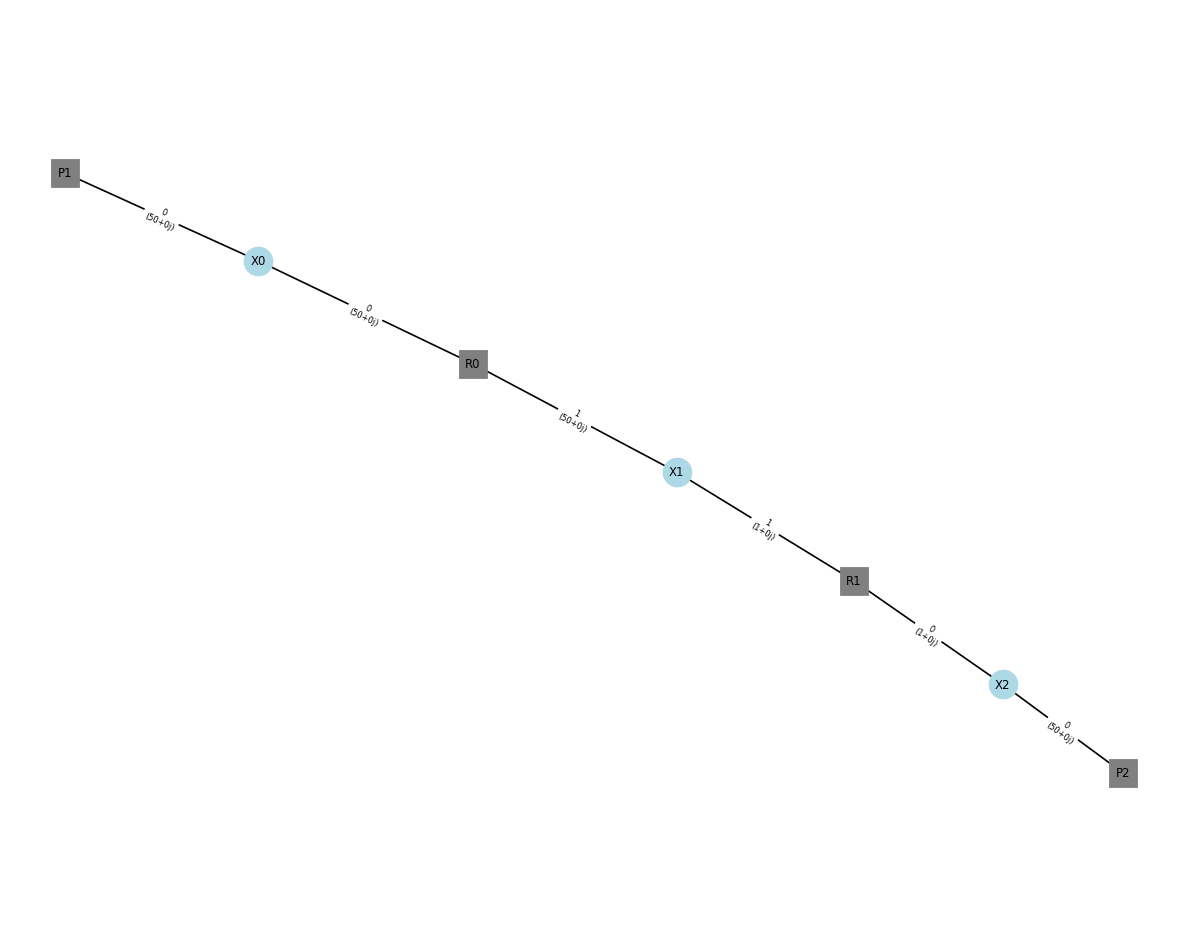

In [5]:
# R-L circuit
connections = [
    [(port1, 0), (R0, 0)],
    [(R0,1), (R1,1)],
    [(R1, 0), (port2, 0)]
]
circuit = Circuit(connections)
#LC_from_circuit = circuit.network
#
# Draw the resulting graph
#
circuit.plot_graph(network_labels=True,edge_labels=True,port_labels=True,inter_labels=True)

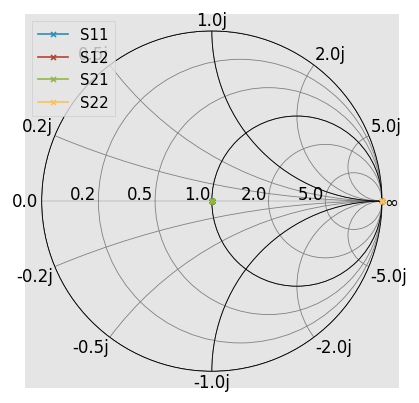

In [6]:
# show the smith chart for the above. 
# https://scikit-rf.readthedocs.io/en/latest/api/generated/skrf.network.Network.plot_s_smith.html
circuit.network.plot_s_smith(draw_labels=True,marker='x')

In [7]:
circuit.network.s[:11,0,1]

array([2.21715674e-180+0.j, 2.21715674e-180+0.j, 2.21715674e-180+0.j,
       2.21715674e-180+0.j, 2.21715674e-180+0.j, 2.21715674e-180+0.j,
       2.21715674e-180+0.j, 2.21715674e-180+0.j, 2.21715674e-180+0.j,
       2.21715674e-180+0.j, 2.21715674e-180+0.j])